In [ ]:
!git clone https://github.com/di89uX/particle-gnn.git



Cloning into 'particle-gnn'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 22 (delta 5), reused 20 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 9.79 KiB | 172.00 KiB/s, done.
Resolving deltas: 100% (5/5), done.


In [ ]:
%cd particle-gnn

/content/particle-gnn


In [ ]:
!pip install torch-geometric h5py

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.0 MB/s eta 0:00:00


In [ ]:
import os
import torch
import h5py
from torch_geometric.data import Data, Dataset
from torch_geometric.loader import DataLoader
from torch.utils.data import ConcatDataset, random_split

# 1. Custom KNN Graph and PyG Graph
def custom_knn_graph(coords, k, loop=True):
    dist_matrix = torch.cdist(coords, coords)
    _, col = torch.topk(-dist_matrix, k=k, dim=1)
    row = torch.arange(coords.size(0)).view(-1, 1).repeat(1, k)
    edge_index = torch.stack([row.flatten(), col.flatten()], dim=0)
    return edge_index

def create_pyg_graph(jet_features, label, k_neighbors=8):
    mask = jet_features[:, 3] > 0.5
    valid_particles = jet_features[mask]
    if len(valid_particles) == 0:
        return None
    node_features = valid_particles[:, 0:3]
    x = torch.tensor(node_features, dtype=torch.float)
    coords = x[:, 0:2]
    actual_k = min(k_neighbors, coords.size(0))
    edge_index = custom_knn_graph(coords, k=actual_k, loop=True)
    y = torch.tensor([label], dtype=torch.long)
    return Data(x=x, edge_index=edge_index, y=y)

from torch.utils.data import Dataset
import h5py
import torch

class JetDataset(Dataset):
    def __init__(self, filepath, label, max_jets=None):
        self.label = label

        # Data reads only once
        with h5py.File(filepath, 'r') as f:
            total_jets = len(f['particle_features'])
            self.num_jets = min(max_jets, total_jets) if max_jets else total_jets

            # store all data to RAM
            self.data_in_memory = f['particle_features'][:self.num_jets]

    def __len__(self):
        return self.num_jets

    def __getitem__(self, idx):
        # keep index in the range
        idx = idx % self.num_jets

        jet_data = self.data_in_memory[idx]
        graph = create_pyg_graph(jet_data, label=self.label)

        # if graph none get other one
        while graph is None:
            idx = (idx + 1) % self.num_jets
            jet_data = self.data_in_memory[idx]
            graph = create_pyg_graph(jet_data, label=self.label)

        return graph

# 3. DataLoaders (Full Dataset)
gluon_path = os.path.join('/content/drive/Othercomputers/My Laptop (2)/D:/particle-gnn/data', 'g.hdf5')
quark_path = os.path.join('/content/drive/Othercomputers/My Laptop (2)/D:/particle-gnn/data', 'q.hdf5')

gluon_dataset = JetDataset(filepath=gluon_path, label=0)
quark_dataset = JetDataset(filepath=quark_path, label=1)

full_dataset = ConcatDataset([gluon_dataset, quark_dataset])
print(f"Total number of Jets: {len(full_dataset)}")

# Seperating the Train & Validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

print(f"Number of Training set data: {len(train_dataset)}")
print(f"Number of Validation set data: {len(val_dataset)}")

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

Total number of Jets: 347931
Number of Training set data: 278344
Number of Validation set data: 69587


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from src.model import ParticleNet
from tqdm.auto import tqdm

#Device Configurations
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {device}")

full_model = ParticleNet(num_node_features=3,num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(full_model.parameters(), lr=0.001)

epochs = 10
history = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}

print("\nStarting the Training...\n")
for epoch in range(1, epochs + 1):
    full_model.train() # Dropout layers
    train_loss = 0
    train_correct = 0
    train_total = 0
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{epoch} [Train]")
    for batch in train_bar:
        batch = batch.to(device) # Data feeding to GPU

        optimizer.zero_grad()
        out = full_model(batch.x, batch.edge_index, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        pred = out.argmax(dim=1)
        train_correct += int((pred == batch.y).sum())
        train_total += batch.y.size(0)
        train_bar.set_postfix({'Loss':f"{loss.item():.4f}",'Acc':f"{train_correct/train_total:.4f}"})

    avg_train_loss = train_loss / len(train_loader)
    train_acc = (train_correct / train_total) * 100


    #(Validation Phase)
    full_model.eval() # Deactivating the Dropout layers
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad(): # In validation gradients aren't calculated using derivation
        for batch in val_loader:
            batch = batch.to(device)
            out = full_model(batch.x, batch.edge_index, batch.batch)
            loss = criterion(out, batch.y)

            val_loss += loss.item()
            pred = out.argmax(dim=1)
            val_correct += int((pred == batch.y).sum())
            val_total += batch.y.size(0)

    avg_val_loss = val_loss / len(val_loader)
    val_acc = (val_correct / val_total) * 100
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f"Epoch {epoch:02d}/{epochs}")
    print(f"  Train -> Loss: {avg_train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f"  Valid -> Loss: {avg_val_loss:.4f} | Acc: {val_acc:.2f}%\n")

print("Training Complete!")

Device : cuda

Starting the Training...



Epoch 01/1 [Train]:   0%|          | 0/8699 [00:00<?, ?it/s]

Epoch 01/10
  Train -> Loss: 0.4986 | Acc: 76.36%
  Valid -> Loss: 0.4834 | Acc: 76.69%



Epoch 02/2 [Train]:   0%|          | 0/8699 [00:00<?, ?it/s]

Epoch 02/10
  Train -> Loss: 0.4780 | Acc: 77.80%
  Valid -> Loss: 0.4608 | Acc: 78.52%



...

Epoch 08/10
  Train -> Loss: 0.4528 | Acc: 79.45%
  Valid -> Loss: 0.4588 | Acc: 79.11%



Epoch 09/9 [Train]:   0%|          | 0/8699 [00:00<?, ?it/s]

Epoch 09/10
  Train -> Loss: 0.4509 | Acc: 79.61%
  Valid -> Loss: 0.4499 | Acc: 79.82%



Epoch 10/10 [Train]:   0%|          | 0/8699 [00:00<?, ?it/s]

Epoch 10/10
  Train -> Loss: 0.4495 | Acc: 79.71%
  Valid -> Loss: 0.4638 | Acc: 78.37%

Training Complete!


Model saved to particle_weights.pth


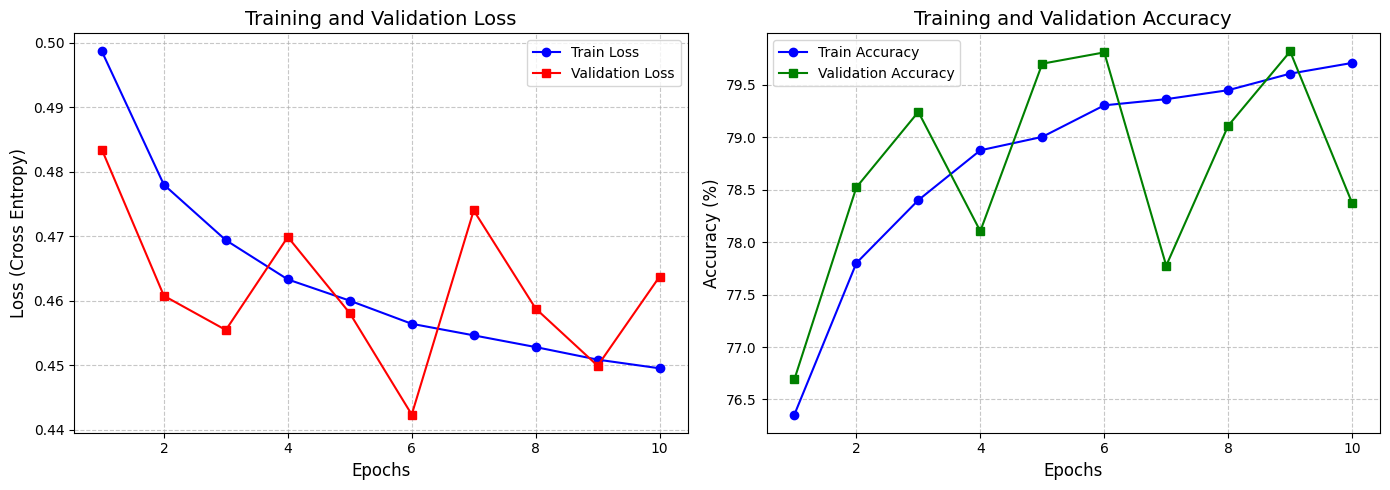

In [ ]:
import matplotlib.pyplot as plt
import torch
model_path = "particle_weights.pth"
torch.save(full_model.state_dict(), model_path)
print(f"Model saved to {model_path}")

epochs_range = range(1, epochs + 1)


plt.figure(figsize=(14, 5))

#Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='blue', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='red', marker='s')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (Cross Entropy)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='blue', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', color='green', marker='s')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()